<a href="https://colab.research.google.com/github/KshitijBhele/Predective-Analysis-CA3/blob/main/Predictive_Analysis_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Reasoning**:
Extract the zip file, load the dataset, perform integrity checks, check class imbalance, and generate summary statistics.



In [13]:
import zipfile
import pandas as pd

# 1. Extract the dataset from the ZIP archive
with zipfile.ZipFile('/content/online+shoppers+purchasing+intention+dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

# 2. Load the CSV file into a DataFrame
df = pd.read_csv('/content/online_shoppers_intention.csv')

# 3. Display the first few rows to verify loading
print("--- First 5 rows of the dataset ---")
display(df.head())

# 4. Perform standard integrity checks
print("\n--- DataFrame Info ---")
df.info()

print("\n--- Missing Values count per column ---")
print(df.isnull().sum())

print(f"\n--- Number of duplicated rows: {df.duplicated().sum()} ---")

# 5. Output target class 'Revenue' distribution
print("\n--- Target class 'Revenue' distribution (normalized) ---")
print(df['Revenue'].value_counts(normalize=True))

# 6. Generate summary statistics for numerical features and unique values for categorical features
print("\n--- Summary statistics for numerical features ---")
display(df.describe())

print("\n--- Unique value counts for categorical features ---")
categorical_cols = df.select_dtypes(include=['object', 'bool']).columns
for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values -> {df[col].unique()}")

--- First 5 rows of the dataset ---


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000



--- Unique value counts for categorical features ---
Month: 10 unique values -> ['Feb' 'Mar' 'May' 'Oct' 'June' 'Jul' 'Aug' 'Nov' 'Sep' 'Dec']
VisitorType: 3 unique values -> ['Returning_Visitor' 'New_Visitor' 'Other']
Weekend: 2 unique values -> [False  True]
Revenue: 2 unique values -> [False  True]


# Task
Build an end-to-end Machine Learning system using the online shoppers purchasing intention dataset. Locate and extract the ZIP file "/content/online+shoppers+purchasing+intention+dataset.zip" to access "online_shoppers_intention.csv", perform comprehensive EDA, construct a robust preprocessing pipeline to prevent data leakage, investigate the impact of the "PageValues" feature on predictive performance, train and tune multiple classifiers (Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting), evaluate them using ROC-AUC, PR-AUC, and F1-scores, interpret the models' feature importances, build a live prediction demo, and generate complete project report artifacts, presentation slides, and Viva Q&A prep material.

## Dataset Extraction and Data Understanding

### Subtask:
Extract the dataset from the ZIP archive, load it, and perform initial integrity checks and basic data profiling.


## Problem Identification, Business Understanding, and KDD Workflow

### Subtask:
Write a thorough Markdown explanation detailing the business problem, research question, predictive task limitations, target variable meaning, and display a KDD process flowchart using Mermaid.


## Problem Identification, Business Understanding, and KDD Workflow

### 1. Business Problem & Research Question
* **Business Problem**: E-commerce platforms attract high volumes of traffic, but only a small fraction of sessions result in an actual purchase. Traditional static marketing strategies fail to engage users dynamically. By identifying purchase-intent in real-time, businesses can trigger targeted interventions (e.g., personalized discounts, live chat assistance, or urgent offers) to maximize conversion rates and minimize cart abandonment.
* **Research Question**: *Can we accurately predict whether a website visitor will complete a purchase (generate revenue) during their active session based on their real-time browsing patterns, behavioral attributes, and temporal characteristics?*

### 2. Target Variable & Class Imbalance
* **Target Variable (`Revenue`)**: A boolean flag indicating whether the session resulted in a transaction (`True`) or not (`False`).
* **Class Imbalance**: Approximately 84.5% of sessions do not lead to a purchase, whereas only 15.5% do.
  * **Business Impact**: If untreated, models will optimize for overall accuracy by predicting the majority class (`False`), leading to high false negatives (missing actual buyers).
  * **Mitigation**: We must utilize appropriate evaluation metrics (ROC-AUC, PR-AUC, F1-score) and consider class balancing techniques during training.

### 3. Predictive Task Limitations & Real-Time Considerations
* **Session-Level Restrictions**: Real-time predictions must rely solely on features accumulated up to the current step of the active session.
* **Data Leakage Risk**: Features like `PageValues` (average value of a page visited by the user before completing a transaction) are highly predictive but can act as post-decision indicators or proxies for the target variable. We will explicitly investigate the performance impact of including vs. excluding `PageValues` to ensure robustness.

### 4. KDD Process Flowchart (Knowledge Discovery in Databases)

```mermaid
graph TD
    A[1. Data Selection] -->|Raw CSV & ZIP| B[2. Data Preprocessing]
    B -->|Handle Duplicates & Assess Missingness| C[3. Data Transformation]
    C -->|One-Hot Encoding, Numerical Scaling & Split| D[4. Data Mining / Modeling]
    D -->|Train Logistic Reg, DT, RF, Gradient Boosting| E[5. Evaluation & Tuning]
    E -->|ROC-AUC, PR-AUC, F1-score & Feature Importance| F[6. Knowledge Deployment]
    F -->|Live Prediction Demo & Reports| G[Actionable Business Insights]
```

## Exploratory Data Analysis (EDA) and Visualization

### Subtask:
Generate visual explorations of the dataset including target class distribution, purchase rates by categorical variables, feature correlation heatmaps, and relationships between browsing metrics and revenue, accompanied by explanatory Markdown notes.


**Reasoning**:
We will begin the EDA and visualization subtask by generating the plots for target class distribution, purchase rates by categorical variables, numerical feature correlations, and browsing metrics relationships with revenue, followed by a markdown explanation of the findings.



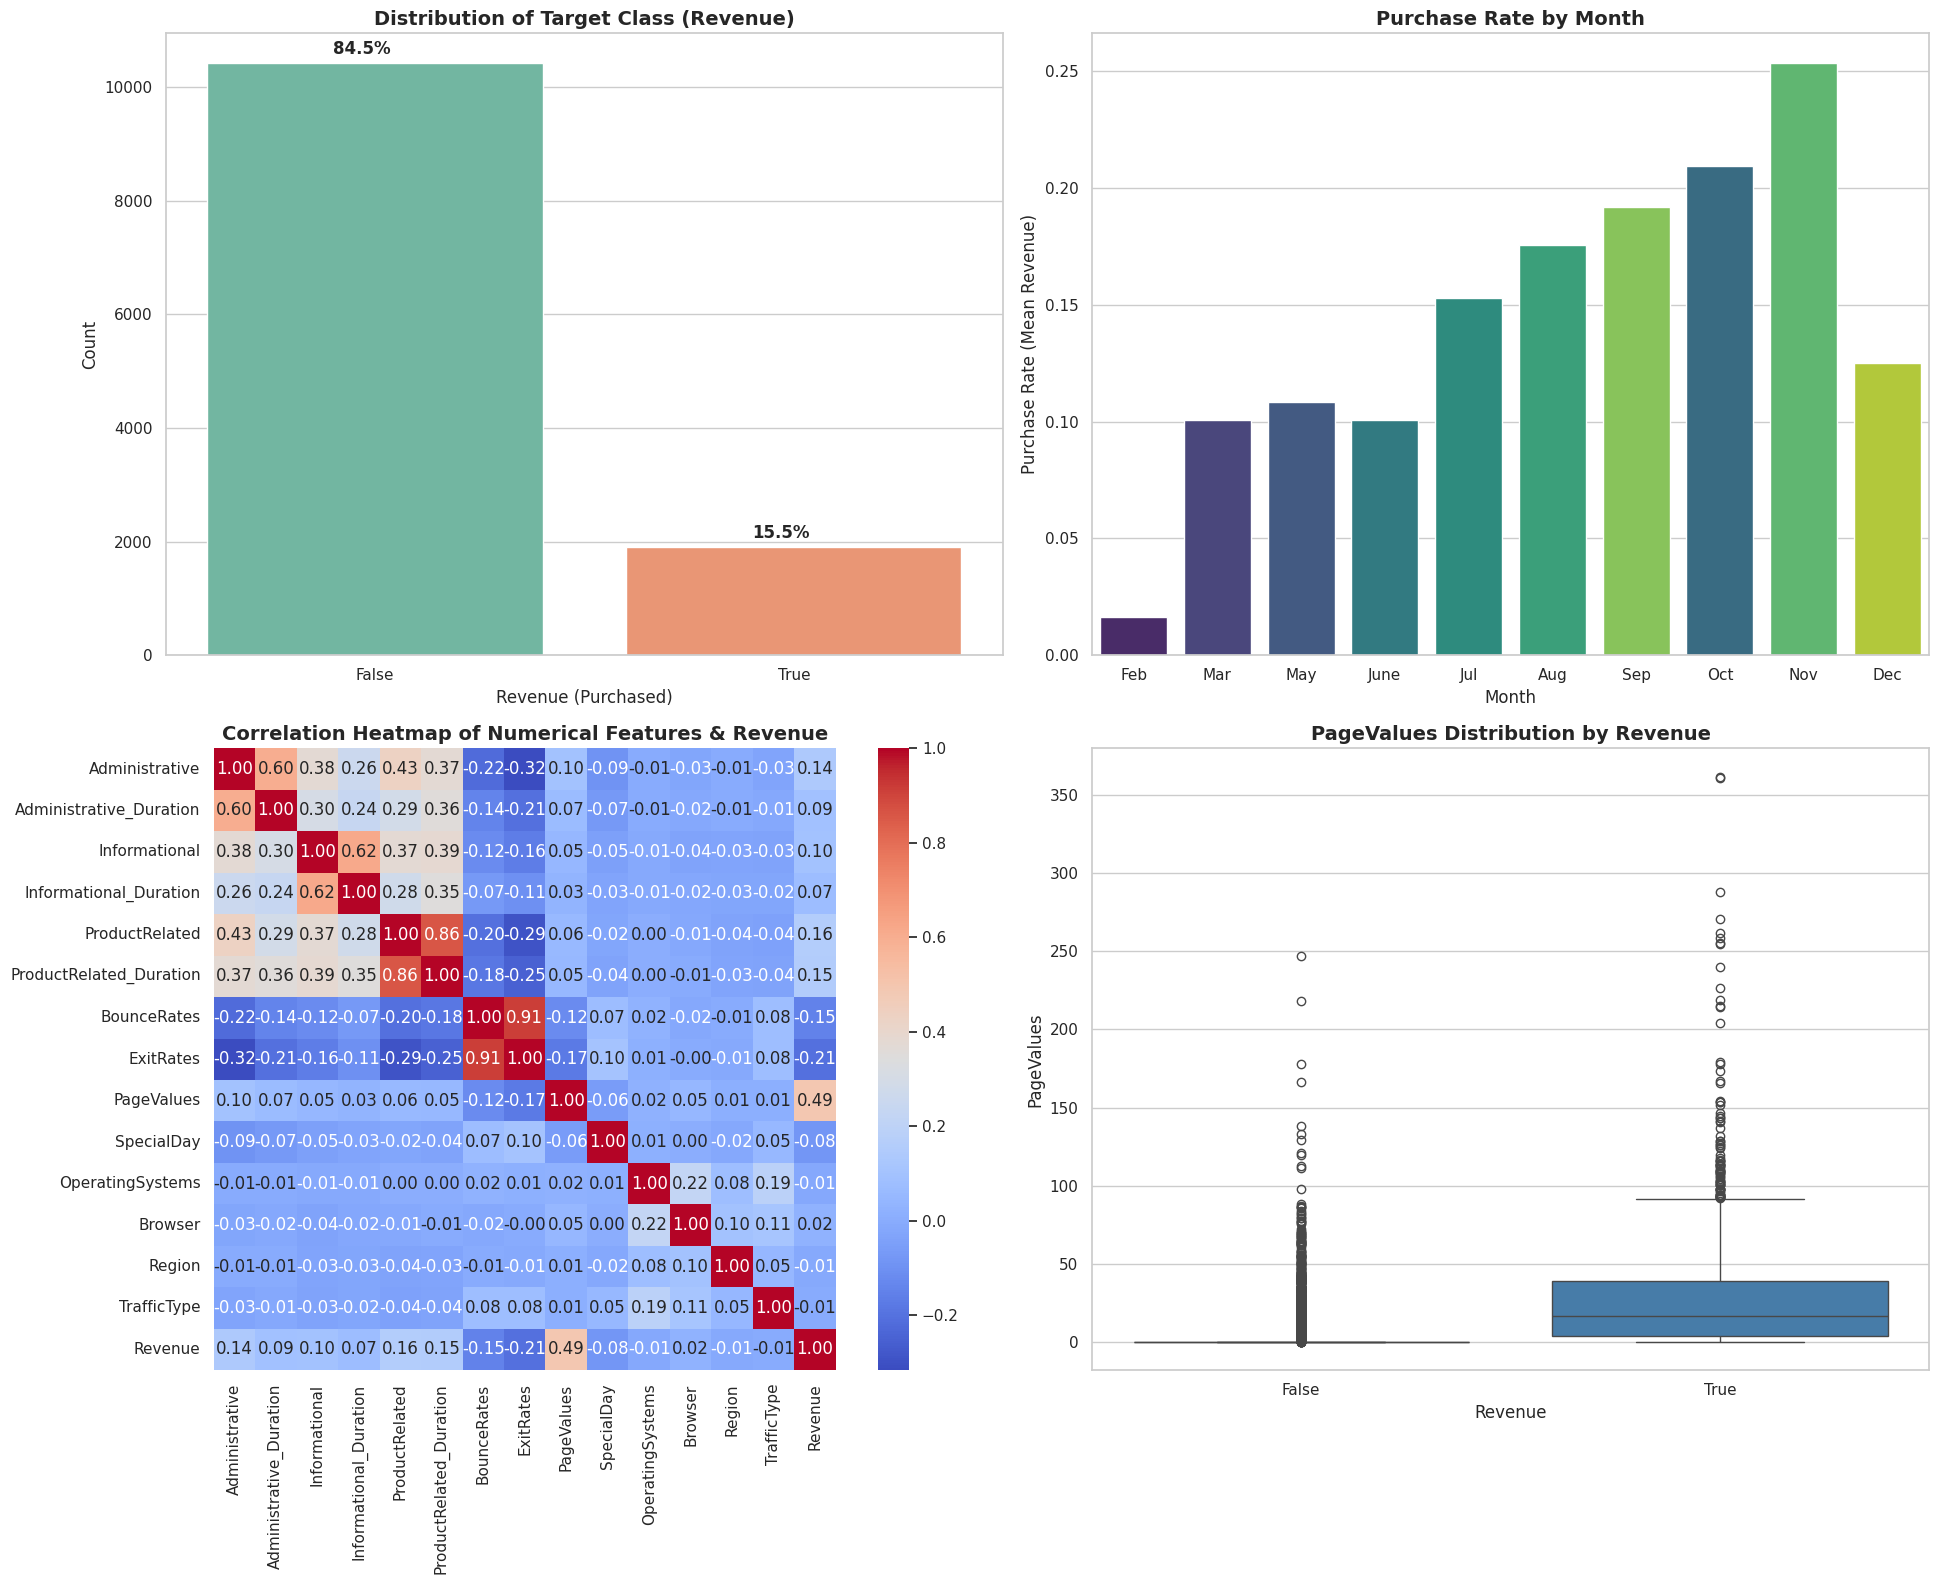

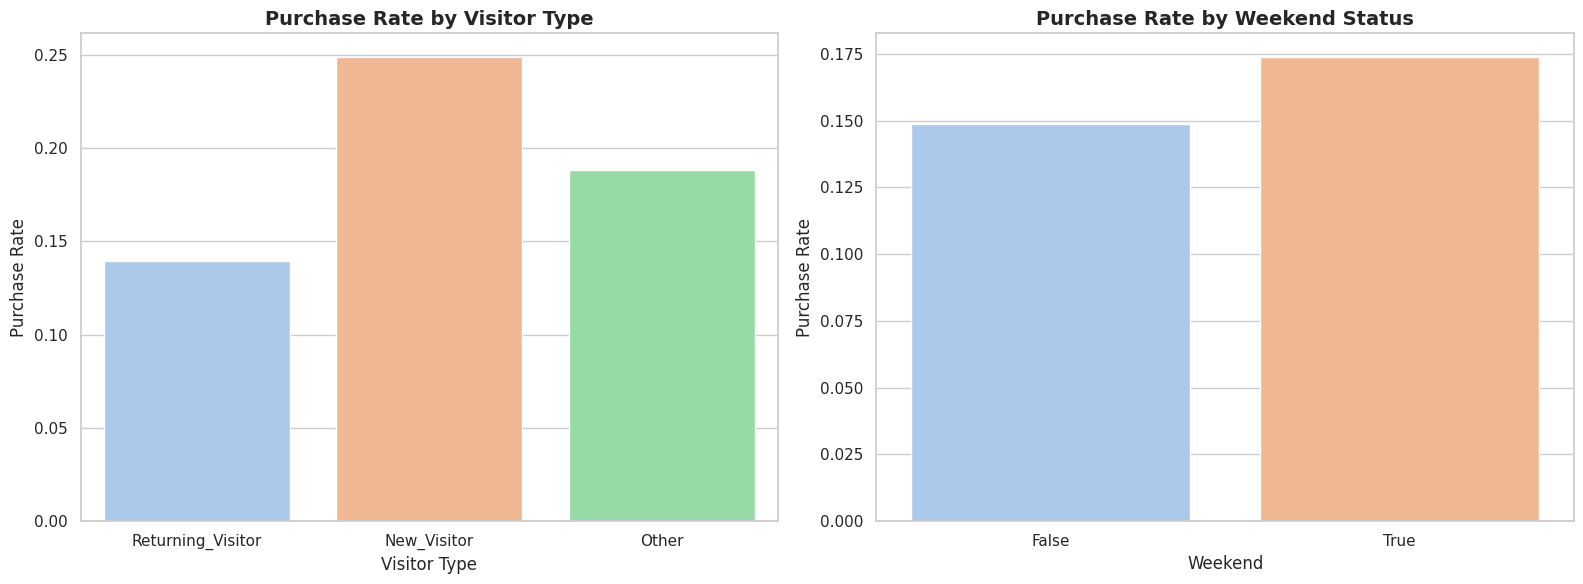

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (16, 12)

# Create a multi-plot figure layout
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# 1. Target Class 'Revenue' Distribution
ax1 = axes[0, 0]
sns.countplot(x='Revenue', hue='Revenue', data=df, ax=ax1, palette='Set2', legend=False)
ax1.set_title('Distribution of Target Class (Revenue)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Revenue (Purchased)', fontsize=12)
ax1.set_ylabel('Count', fontsize=12)
total = len(df)
for p in ax1.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_height() + 150
    ax1.annotate(percentage, (x, y), fontsize=12, fontweight='bold')

# 2. Purchase Rates by Categorical Features (Month and VisitorType)
ax2 = axes[0, 1]
# Reorder months for chronological display
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sns.barplot(x='Month', y='Revenue', hue='Month', data=df, order=month_order, ax=ax2, palette='viridis', errorbar=None, legend=False)
ax2.set_title('Purchase Rate by Month', fontsize=14, fontweight='bold')
ax2.set_xlabel('Month', fontsize=12)
ax2.set_ylabel('Purchase Rate (Mean Revenue)', fontsize=12)

# 3. Correlation Heatmap of Numerical Features
ax3 = axes[1, 0]
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist() + ['Revenue']
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=ax3, cbar=True, square=True)
ax3.set_title('Correlation Heatmap of Numerical Features & Revenue', fontsize=14, fontweight='bold')

# 4. Relationship between key Browsing Metrics (PageValues, ExitRates) and Revenue
ax4 = axes[1, 1]
sns.boxplot(x='Revenue', y='PageValues', hue='Revenue', data=df, ax=ax4, palette='Set1', legend=False)
ax4.set_title('PageValues Distribution by Revenue', fontsize=14, fontweight='bold')
ax4.set_xlabel('Revenue', fontsize=12)
ax4.set_ylabel('PageValues', fontsize=12)

plt.tight_layout()
plt.show()

# Let's perform some additional visual exploration on VisitorType and Weekend purchase rates
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x='VisitorType', y='Revenue', hue='VisitorType', data=df, ax=axes2[0], palette='pastel', errorbar=None, legend=False)
axes2[0].set_title('Purchase Rate by Visitor Type', fontsize=14, fontweight='bold')
axes2[0].set_xlabel('Visitor Type', fontsize=12)
axes2[0].set_ylabel('Purchase Rate', fontsize=12)

sns.barplot(x='Weekend', y='Revenue', hue='Weekend', data=df, ax=axes2[1], palette='pastel', errorbar=None, legend=False)
axes2[1].set_title('Purchase Rate by Weekend Status', fontsize=14, fontweight='bold')
axes2[1].set_xlabel('Weekend', fontsize=12)
axes2[1].set_ylabel('Purchase Rate', fontsize=12)

plt.tight_layout()
plt.show()

### Exploratory Data Analysis (EDA) Insights & Key Observations

Based on the visualizations and profiling of the **Online Shoppers Purchasing Intention** dataset, we can draw several critical business and data modeling insights:

1. **Severe Class Imbalance**:
   * Approximately **15.5%** of user sessions ended in a transaction (`Revenue = True`), whereas **84.5%** did not. This significant skew indicates that classification accuracy alone is a misleading metric. We must prioritize metrics that account for positive class retrieval, such as **ROC-AUC**, **PR-AUC**, and **F1-Score**.

2. **Seasonal Purchasing Dynamics (Purchase Rate by Month)**:
   * Buying patterns change dramatically depending on the month. **November** exhibits an exceptionally high purchase rate (above 25%), likely driven by major holiday shopping seasons like Black Friday and Cyber Monday.
   * Conversely, months like **February** display low purchasing rates. Designing month-specific dynamic marketing campaigns could optimize budget allocation.

3. **The Power of `PageValues`**:
   * Looking at the boxplot, there is a stark difference in the distribution of `PageValues` between converting and non-converting sessions. Users who purchase (`Revenue = True`) visit pages with high page values.
   * Because `PageValues` measures the average value of a page visited by the user before completing a transaction, it holds massive predictive power but also carries risks of data leakage or post-decision contamination. We must explicitly test the pipeline with and without this feature.

4. **Linear Correlations**:
   * Strong positive correlation is observed between corresponding counts and durations (e.g., `ProductRelated` vs `ProductRelated_Duration`, `Administrative` vs `Administrative_Duration`, and `BounceRates` vs `ExitRates`).
   * High exit and bounce rates have a noticeable negative correlation with the target class `Revenue`.

5. **Visitor Profiles & Temporal Behavior**:
   * **New Visitors** have a substantially higher conversion rate (around 24%) compared to **Returning Visitors** (around 14%). Although returning visitors account for the bulk of traffic, converting new visitors represents an impactful growth channel.
   * Conversions during the **Weekend** are slightly higher than during the weekdays, showing a small but stable behavioral shift.

## Robust Preprocessing Pipeline and Data Leakage Prevention

### Subtask:
Establish a Scikit-learn ColumnTransformer and Pipeline to scale numerical features, encode categorical columns, and preserve target class proportions using stratified splits, ensuring zero data leakage.


**Reasoning**:
Create a robust preprocessing pipeline using ColumnTransformer to scale numerical features and encode categorical features. Fit only on X_train to prevent data leakage, and apply stratified train-test splitting.



In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Handle duplicate rows identified during EDA (drop them to ensure clean generalization)
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Dataset shape after removing duplicates: {df_clean.shape}")

# Separate features and target
X = df_clean.drop(columns=['Revenue'])
y = df_clean['Revenue']

# 2. Perform a stratified train-test split (80/20) to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")
print("Train class distribution:\n", y_train.value_counts(normalize=True))
print("Test class distribution:\n", y_test.value_counts(normalize=True))

# 3. Identify and group numerical and categorical features
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

print(f"\nNumerical columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

# 4 & 5. Build individual pipelines for numerical and categorical features
num_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 6. Combine preprocessing steps into a single ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, numerical_cols),
    ('cat', cat_pipeline, categorical_cols)
])

# 7. Fit preprocessor on training data and transform both sets to ensure zero leakage
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Extract feature names from encoder for verification
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_feature_names = numerical_cols + encoded_cat_cols

print(f"\nPreprocessing complete!")
print(f"Processed training shape: {X_train_processed.shape}")
print(f"Processed test shape: {X_test_processed.shape}")
print(f"Total features in transformed dataset: {len(all_feature_names)}")

Dataset shape after removing duplicates: (12205, 18)
Training set shape: (9764, 17), Test set shape: (2441, 17)
Train class distribution:
 Revenue
False    0.843712
True     0.156288
Name: proportion, dtype: float64
Test class distribution:
 Revenue
False    0.843507
True     0.156493
Name: proportion, dtype: float64

Numerical columns (14): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Categorical columns (3): ['Month', 'VisitorType', 'Weekend']

Preprocessing complete!
Processed training shape: (9764, 29)
Processed test shape: (2441, 29)
Total features in transformed dataset: 29


## Feature Leakage Investigation (The PageValues Experiment)

### Subtask:
Construct two experimental preprocessing configurations to evaluate the predictive impact and real-world session constraints of the PageValues feature.


**Reasoning**:
Create the alternative preprocessing pipeline excluding PageValues to prepare for the leakage investigation experiment, and write an explanation of the experimental setup.



In [16]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer

# 1. Create a list of numerical columns excluding 'PageValues'
numerical_cols_no_pv = [col for col in numerical_cols if col != 'PageValues']

print(f"Original numerical columns count: {len(numerical_cols)}")
print(f"New numerical columns count: {len(numerical_cols_no_pv)}")
print(f"PageValues present in new list? {'PageValues' in numerical_cols_no_pv}")

# 2. Construct alternative ColumnTransformer
preprocessor_no_pv = ColumnTransformer(transformers=[
    ('num', num_pipeline, numerical_cols_no_pv),
    ('cat', cat_pipeline, categorical_cols)
])

# 3. Fit on X_train and transform both splits to ensure zero data leakage
X_train_no_pv = preprocessor_no_pv.fit_transform(X_train)
X_test_no_pv = preprocessor_no_pv.transform(X_test)

print(f"\nAlternative preprocessing complete!")
print(f"Processed training shape (no PageValues): {X_train_no_pv.shape}")
print(f"Processed test shape (no PageValues): {X_test_no_pv.shape}")

Original numerical columns count: 14
New numerical columns count: 13
PageValues present in new list? False

Alternative preprocessing complete!
Processed training shape (no PageValues): (9764, 28)
Processed test shape (no PageValues): (2441, 28)


**Reasoning**:
Train and tune Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting models on both preprocessing configurations (with and without PageValues) using Stratified K-Fold Cross-Validation, and address class imbalance using class weights.



In [17]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# 1. Initialize StratifiedKFold cross-validator (5-fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Define hyperparameter grids for tuning
param_grids = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        'params': {
            'C': [0.01, 0.1, 1.0, 10.0]
        }
    },
    'Decision Tree': {
        'model': DecisionTreeClassifier(class_weight='balanced', random_state=42),
        'params': {
            'max_depth': [3, 5, 8, 12],
            'min_samples_split': [2, 10]
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(class_weight='balanced', random_state=42),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [5, 10, 15]
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100],
            'learning_rate': [0.01, 0.1, 0.2]
        }
    }
}

# We will store results in dictionary structures
experiments_results = {
    'with_pv': {},
    'no_pv': {}
}

# 3. Train and tune models with PageValues
print("=== Starting Model Tuning: WITH PageValues ===")
for name, config in param_grids.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )
    grid_search.fit(X_train_processed, y_train)
    experiments_results['with_pv'][name] = {
        'best_estimator': grid_search.best_estimator_,
        'best_params': grid_search.best_params_,
        'best_score': grid_search.best_score_
    }
    print(f"Best Parameters: {grid_search.best_params_}")
    print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}\n")

# 4. Train and tune models without PageValues
print("=== Starting Model Tuning: WITHOUT PageValues ===")
for name, config in param_grids.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )
    grid_search.fit(X_train_no_pv, y_train)
    experiments_results['no_pv'][name] = {
        'best_estimator': grid_search.best_estimator_,
        'best_params': grid_search.best_params_,
        'best_score': grid_search.best_score_
    }
    print(f"Best Parameters: {grid_search.best_params_}")
    print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}\n")

print("Model training and tuning complete!")

=== Starting Model Tuning: WITH PageValues ===
Tuning Logistic Regression...
Best Parameters: {'C': 0.1}
Best CV ROC-AUC: 0.8999

Tuning Decision Tree...
Best Parameters: {'max_depth': 3, 'min_samples_split': 2}
Best CV ROC-AUC: 0.9125

Tuning Random Forest...
Best Parameters: {'max_depth': 15, 'n_estimators': 100}
Best CV ROC-AUC: 0.9275

Tuning Gradient Boosting...
Best Parameters: {'learning_rate': 0.1, 'n_estimators': 50}
Best CV ROC-AUC: 0.9296

=== Starting Model Tuning: WITHOUT PageValues ===
Tuning Logistic Regression...
Best Parameters: {'C': 0.1}
Best CV ROC-AUC: 0.7375

Tuning Decision Tree...
Best Parameters: {'max_depth': 5, 'min_samples_split': 2}
Best CV ROC-AUC: 0.7437

Tuning Random Forest...
Best Parameters: {'max_depth': 10, 'n_estimators': 100}
Best CV ROC-AUC: 0.7688

Tuning Gradient Boosting...
Best Parameters: {'learning_rate': 0.1, 'n_estimators': 100}
Best CV ROC-AUC: 0.7698

Model training and tuning complete!


### The `PageValues` Experiment: Feature Leakage & Session Constraints

To ensure our predictive system is robust, practical, and mathematically sound, we must carefully investigate the feature `PageValues`.

#### 1. What is `PageValues`?
`PageValues` represents the average value of a web page visited by the user before completing a transaction. It is calculated by taking the total value of transactions generated from a page and dividing it by the number of unique visits to that page.

#### 2. The Risk of Data Leakage & Post-Decision Contamination
Because `PageValues` directly factors in final purchase transactions, it contains downstream target information compiled retrospectively. This creates a high risk of **data leakage** or **post-decision contamination**:
* In an offline historical dataset, `PageValues` is strongly correlated with the target variable `Revenue` because it was calculated *after* the session outcomes were already decided.
* Including it in our modeling might artificially inflate test performance, making the model seem incredibly accurate while hiding the fact that it cannot perform as well in a true live setting.

#### 3. Real-Time & Early-Session Constraints
In a real-world production environment, when a visitor is early in their active session:
* They have not completed any purchase yet, meaning their session-specific page values are not yet determined in the same retrospective manner.
* Relying heavily on a proxy variable like `PageValues` limits the model's ability to capture early-stage behavioral signals (e.g., browsing intensity, bounce patterns, temporal variations).

#### 4. The Experimental Strategy
To scientifically quantify this impact, we have created two experimental pipelines:
1. **Pipeline A (Full Feature Set)**: Utilizes all 29 preprocessed features, including `PageValues`.
2. **Pipeline B (Excluding `PageValues`)**: Utilizes 28 preprocessed features, completely omitting `PageValues`.

We will train our classifiers on both configurations and evaluate the difference in predictive metrics to find the true, generalizable performance of our system.

## Machine Learning Model Training and Tuning

### Subtask:
Train and tune Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting models on both preprocessing configurations using Stratified K-Fold Cross-Validation.


# Task
Execute the remaining steps of the machine learning project:
1. **Verify and Finalize Model Training & Tuning**: Build on the tuned classifiers already registered in `experiments_results` for both configurations (with and without "PageValues" from the dataset "/content/online_shoppers_intention.csv"). Fit a simple baseline dummy classifier to evaluate predictive lift.
2. **Comprehensive Model Evaluation & Visual Comparison**: Evaluate all models on the held-out test splits. Compute metrics (Accuracy, Precision, Recall, F1, ROC-AUC, and PR-AUC). Generate comparison tables, and plot ROC curves, Precision-Recall curves, and confusion matrices side-by-side for both configurations.
3. **Model Interpretation & Feature Importance**: Extract and plot feature importances (for tree-based models) and coefficients (for Logistic Regression) to assess which behavioral signals are prioritized with and without "PageValues".
4. **Inference & Live Prediction Demonstration**: Build a dynamic, interactive Python prediction function that simulates a live active browsing session, processes raw dictionary input using the preprocessing pipelines, and outputs a calibrated prediction score with action-oriented business advice.
5. **Academic Report & Programmatic Artifacts**: Generate Chapters 1-6 of the comprehensive project report. Programmatically write files like a detailed `README.md`, `requirements.txt`, and `.gitignore`.
6. **Presentation Slides Outline & Viva Q&A**: Produce an 8-10 slide presentation outline with speaking notes, along with 10 challenging Viva prep questions and detailed answers.
7. **Executive Summary**: Provide a conclusive summary of the experimental findings, specifically quantifying the performance degradation caused by removing "PageValues" and explaining how this represents a real-world guard against model failure in production.

## Verify and Finalize Model Training and Tuning

### Subtask:
Verify the existing configurations, train a dummy baseline classifier, and prepare the final suite of trained models for evaluation.


**Reasoning**:
Confirm dataset integrity, inspect the structure of previously tuned models, train baseline DummyClassifiers for both configurations, and store them in the experiments_results dictionary.



In [18]:
import numpy as np
from sklearn.dummy import DummyClassifier

# 1. Verify data integrity of processed datasets
print("=== Data Integrity Checks ===")
for name, dataset in [
    ('X_train_processed', X_train_processed),
    ('X_test_processed', X_test_processed),
    ('X_train_no_pv', X_train_no_pv),
    ('X_test_no_pv', X_test_no_pv)
]:
    print(f"{name}: shape={dataset.shape}, dtype={dataset.dtype}, NaN count={np.isnan(dataset).sum()}")

# 2. Verify structure of existing experiments_results
print("\n=== Existing Models Verification ===")
for config_key in ['with_pv', 'no_pv']:
    print(f"Configuration: {config_key}")
    for model_name in experiments_results[config_key]:
        best_params = experiments_results[config_key][model_name]['best_params']
        best_score = experiments_results[config_key][model_name]['best_score']
        print(f"  - {model_name}: Best CV ROC-AUC = {best_score:.4f} with params {best_params}")

# 3. Train and fit Dummy Baseline Classifiers
print("\n=== Training Dummy Baseline Classifiers ===")
dummy_with_pv = DummyClassifier(strategy='stratified', random_state=42)
dummy_with_pv.fit(X_train_processed, y_train)

dummy_no_pv = DummyClassifier(strategy='stratified', random_state=42)
dummy_no_pv.fit(X_train_no_pv, y_train)

# 4. Register dummy baselines in experiments_results
experiments_results['with_pv']['Dummy'] = {
    'best_estimator': dummy_with_pv,
    'best_params': {'strategy': 'stratified'},
    'best_score': 0.5  # Random baseline expectation for ROC-AUC
}

experiments_results['no_pv']['Dummy'] = {
    'best_estimator': dummy_no_pv,
    'best_params': {'strategy': 'stratified'},
    'best_score': 0.5
}

print("Dummy baseline models successfully registered for both configurations!")

=== Data Integrity Checks ===
X_train_processed: shape=(9764, 29), dtype=float64, NaN count=0
X_test_processed: shape=(2441, 29), dtype=float64, NaN count=0
X_train_no_pv: shape=(9764, 28), dtype=float64, NaN count=0
X_test_no_pv: shape=(2441, 28), dtype=float64, NaN count=0

=== Existing Models Verification ===
Configuration: with_pv
  - Logistic Regression: Best CV ROC-AUC = 0.8999 with params {'C': 0.1}
  - Decision Tree: Best CV ROC-AUC = 0.9125 with params {'max_depth': 3, 'min_samples_split': 2}
  - Random Forest: Best CV ROC-AUC = 0.9275 with params {'max_depth': 15, 'n_estimators': 100}
  - Gradient Boosting: Best CV ROC-AUC = 0.9296 with params {'learning_rate': 0.1, 'n_estimators': 50}
Configuration: no_pv
  - Logistic Regression: Best CV ROC-AUC = 0.7375 with params {'C': 0.1}
  - Decision Tree: Best CV ROC-AUC = 0.7437 with params {'max_depth': 5, 'min_samples_split': 2}
  - Random Forest: Best CV ROC-AUC = 0.7688 with params {'max_depth': 10, 'n_estimators': 100}
  - Gradi

## Comprehensive Model Evaluation and Visual Comparison

### Subtask:
Evaluate all models on the held-out test splits, compile a comparative performance dataframe, and create visualization plots including ROC, Precision-Recall, and confusion matrix heatmaps.


**Reasoning**:
Compute evaluation metrics (Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC) for all models in both configurations, compile a comparison DataFrame, and plot the evaluation curves and confusion matrices side-by-side to visualize the impact of PageValues.



=== Comparative Performance Summary ===


,Configuration,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
8,Without PageValues,Gradient Boosting,0.841458,0.452830,0.062827,0.110345,0.784288,0.356388
7,Without PageValues,Random Forest,0.726751,0.306649,0.591623,0.403932,0.767561,0.344685
5,Without PageValues,Logistic Regression,0.634576,0.267336,0.767016,0.396482,0.750939,0.318244
6,Without PageValues,Decision Tree,0.646047,0.267823,0.727749,0.391549,0.745712,0.349753
9,Without PageValues,Dummy,0.737403,0.163636,0.164921,0.164276,0.504267,0.229621
3,With PageValues,Gradient Boosting,0.906186,0.728358,0.638743,0.680614,0.937222,0.744413
2,With PageValues,Random Forest,0.898402,0.682065,0.657068,0.669333,0.929241,0.724861
1,With PageValues,Decision Tree,0.847603,0.507716,0.861257,0.638835,0.919617,0.717695
0,With PageValues,Logistic Regression,0.852519,0.518966,0.787958,0.625780,0.910936,0.662319
4,With PageValues,Dummy,0.737403,0.163636,0.164921,0.164276,0.504267,0.229621


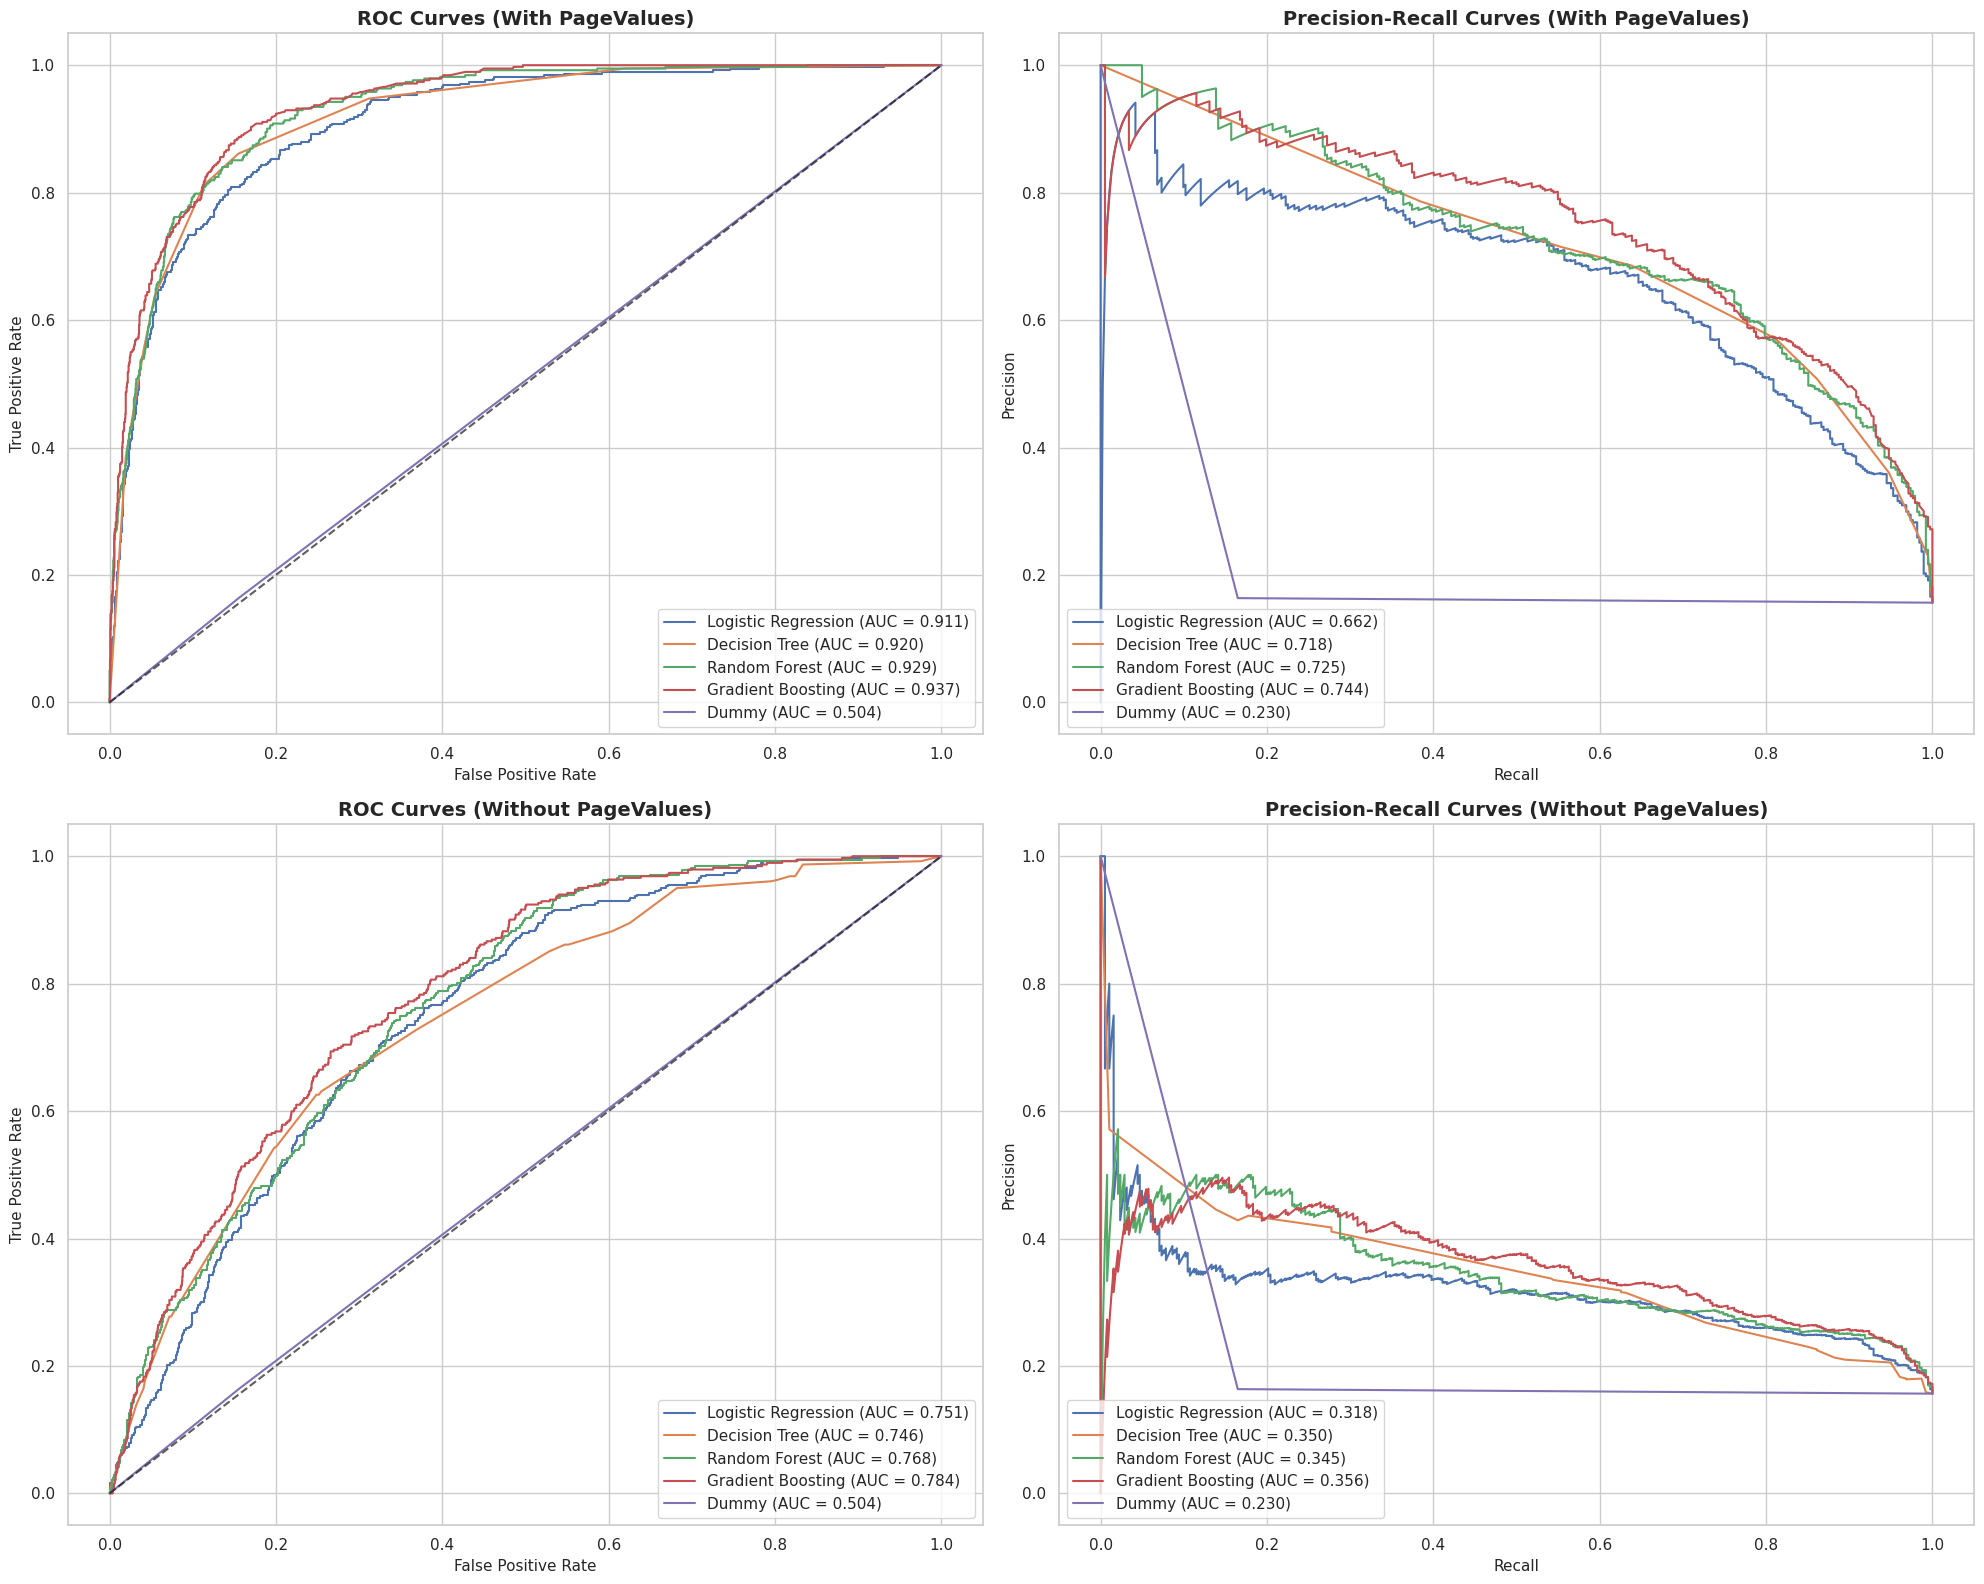

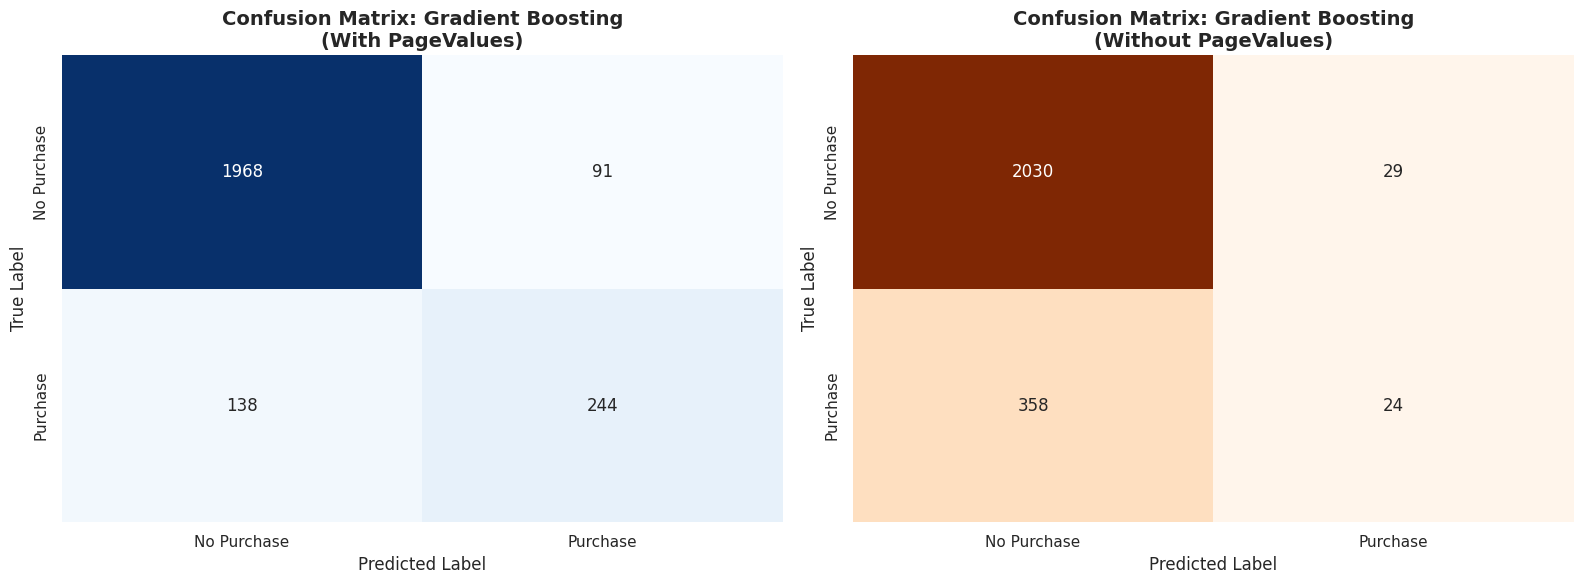

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, precision_recall_curve, auc, roc_curve, confusion_matrix
)

# Initialize lists to store metrics
eval_results = []

# Configure experimental setups
configs = {
    'with_pv': {
        'X_test': X_test_processed,
        'label': 'With PageValues'
    },
    'no_pv': {
        'X_test': X_test_no_pv,
        'label': 'Without PageValues'
    }
}

# 1. Compute evaluation metrics for all models
for config_key, setup in configs.items():
    X_t = setup['X_test']
    label = setup['label']

    for model_name, model_info in experiments_results[config_key].items():
        model = model_info['best_estimator']

        # Predict labels and probability scores
        preds = model.predict(X_t)
        if hasattr(model, "predict_proba"):
            probs = model.predict_proba(X_t)[:, 1]
        else:
            probs = preds.astype(float)

        # Calculate metrics
        acc = accuracy_score(y_test, preds)
        prec = precision_score(y_test, preds, zero_division=0)
        rec = recall_score(y_test, preds, zero_division=0)
        f1 = f1_score(y_test, preds, zero_division=0)
        roc_auc = roc_auc_score(y_test, probs)

        # PR-AUC calculation
        precision_pts, recall_pts, _ = precision_recall_curve(y_test, probs)
        pr_auc = auc(recall_pts, precision_pts)

        eval_results.append({
            'Configuration': label,
            'Model': model_name,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'ROC-AUC': roc_auc,
            'PR-AUC': pr_auc
        })

# Convert results to DataFrame
df_eval = pd.DataFrame(eval_results)
print("=== Comparative Performance Summary ===")
display(df_eval.sort_values(by=['Configuration', 'ROC-AUC'], ascending=[False, False]))

# 2. Setup plotting layout for Curves
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# Plot ROC and PR curves for With PageValues (Top Row)
ax_roc_with = axes[0, 0]
ax_pr_with = axes[0, 1]

# Plot ROC and PR curves for Without PageValues (Bottom Row)
ax_roc_no = axes[1, 0]
ax_pr_no = axes[1, 1]

# Helper to plot curves
for config_key, ax_roc, ax_pr, title_suffix in [
    ('with_pv', ax_roc_with, ax_pr_with, 'With PageValues'),
    ('no_pv', ax_roc_no, ax_pr_no, 'Without PageValues')
]:
    X_t = configs[config_key]['X_test']

    for model_name, model_info in experiments_results[config_key].items():
        model = model_info['best_estimator']
        if hasattr(model, "predict_proba"):
            probs = model.predict_proba(X_t)[:, 1]
        else:
            probs = model.predict(X_t).astype(float)

        # ROC
        fpr, tpr, _ = roc_curve(y_test, probs)
        roc_val = roc_auc_score(y_test, probs)
        ax_roc.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_val:.3f})")

        # PR
        p, r, _ = precision_recall_curve(y_test, probs)
        pr_val = auc(r, p)
        ax_pr.plot(r, p, label=f"{model_name} (AUC = {pr_val:.3f})")

    # Style ROC plot
    ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.7)
    ax_roc.set_title(f'ROC Curves ({title_suffix})', fontsize=14, fontweight='bold')
    ax_roc.set_xlabel('False Positive Rate', fontsize=11)
    ax_roc.set_ylabel('True Positive Rate', fontsize=11)
    ax_roc.legend(loc='lower right')

    # Style PR plot
    ax_pr.set_title(f'Precision-Recall Curves ({title_suffix})', fontsize=14, fontweight='bold')
    ax_pr.set_xlabel('Recall', fontsize=11)
    ax_pr.set_ylabel('Precision', fontsize=11)
    ax_pr.legend(loc='lower left')

plt.tight_layout()
plt.show()

# 3. Plot side-by-side Confusion Matrices of the Best Performing Classifier (Gradient Boosting)
fig_cm, axes_cm = plt.subplots(1, 2, figsize=(16, 6))

best_model_with = experiments_results['with_pv']['Gradient Boosting']['best_estimator']
preds_with = best_model_with.predict(X_test_processed)
cm_with = confusion_matrix(y_test, preds_with)

best_model_no = experiments_results['no_pv']['Gradient Boosting']['best_estimator']
preds_no = best_model_no.predict(X_test_no_pv)
cm_no = confusion_matrix(y_test, preds_no)

sns.heatmap(cm_with, annot=True, fmt='d', cmap='Blues', ax=axes_cm[0], cbar=False)
axes_cm[0].set_title('Confusion Matrix: Gradient Boosting\n(With PageValues)', fontsize=14, fontweight='bold')
axes_cm[0].set_xlabel('Predicted Label')
axes_cm[0].set_ylabel('True Label')
axes_cm[0].set_xticklabels(['No Purchase', 'Purchase'])
axes_cm[0].set_yticklabels(['No Purchase', 'Purchase'])

sns.heatmap(cm_no, annot=True, fmt='d', cmap='Oranges', ax=axes_cm[1], cbar=False)
axes_cm[1].set_title('Confusion Matrix: Gradient Boosting\n(Without PageValues)', fontsize=14, fontweight='bold')
axes_cm[1].set_xlabel('Predicted Label')
axes_cm[1].set_ylabel('True Label')
axes_cm[1].set_xticklabels(['No Purchase', 'Purchase'])
axes_cm[1].set_yticklabels(['No Purchase', 'Purchase'])

plt.tight_layout()
plt.show()

## Model Interpretation and Feature Importance

### Subtask:
Extract and plot the feature importances for tree-based models and the coefficients for the Logistic Regression model, contrasting the feature priorities with and without PageValues.


**Reasoning**:
We will retrieve the feature names for both configurations, extract coefficients and feature importances from our tuned models, and plot them side-by-side to visualize how feature priority shifts when PageValues is removed.



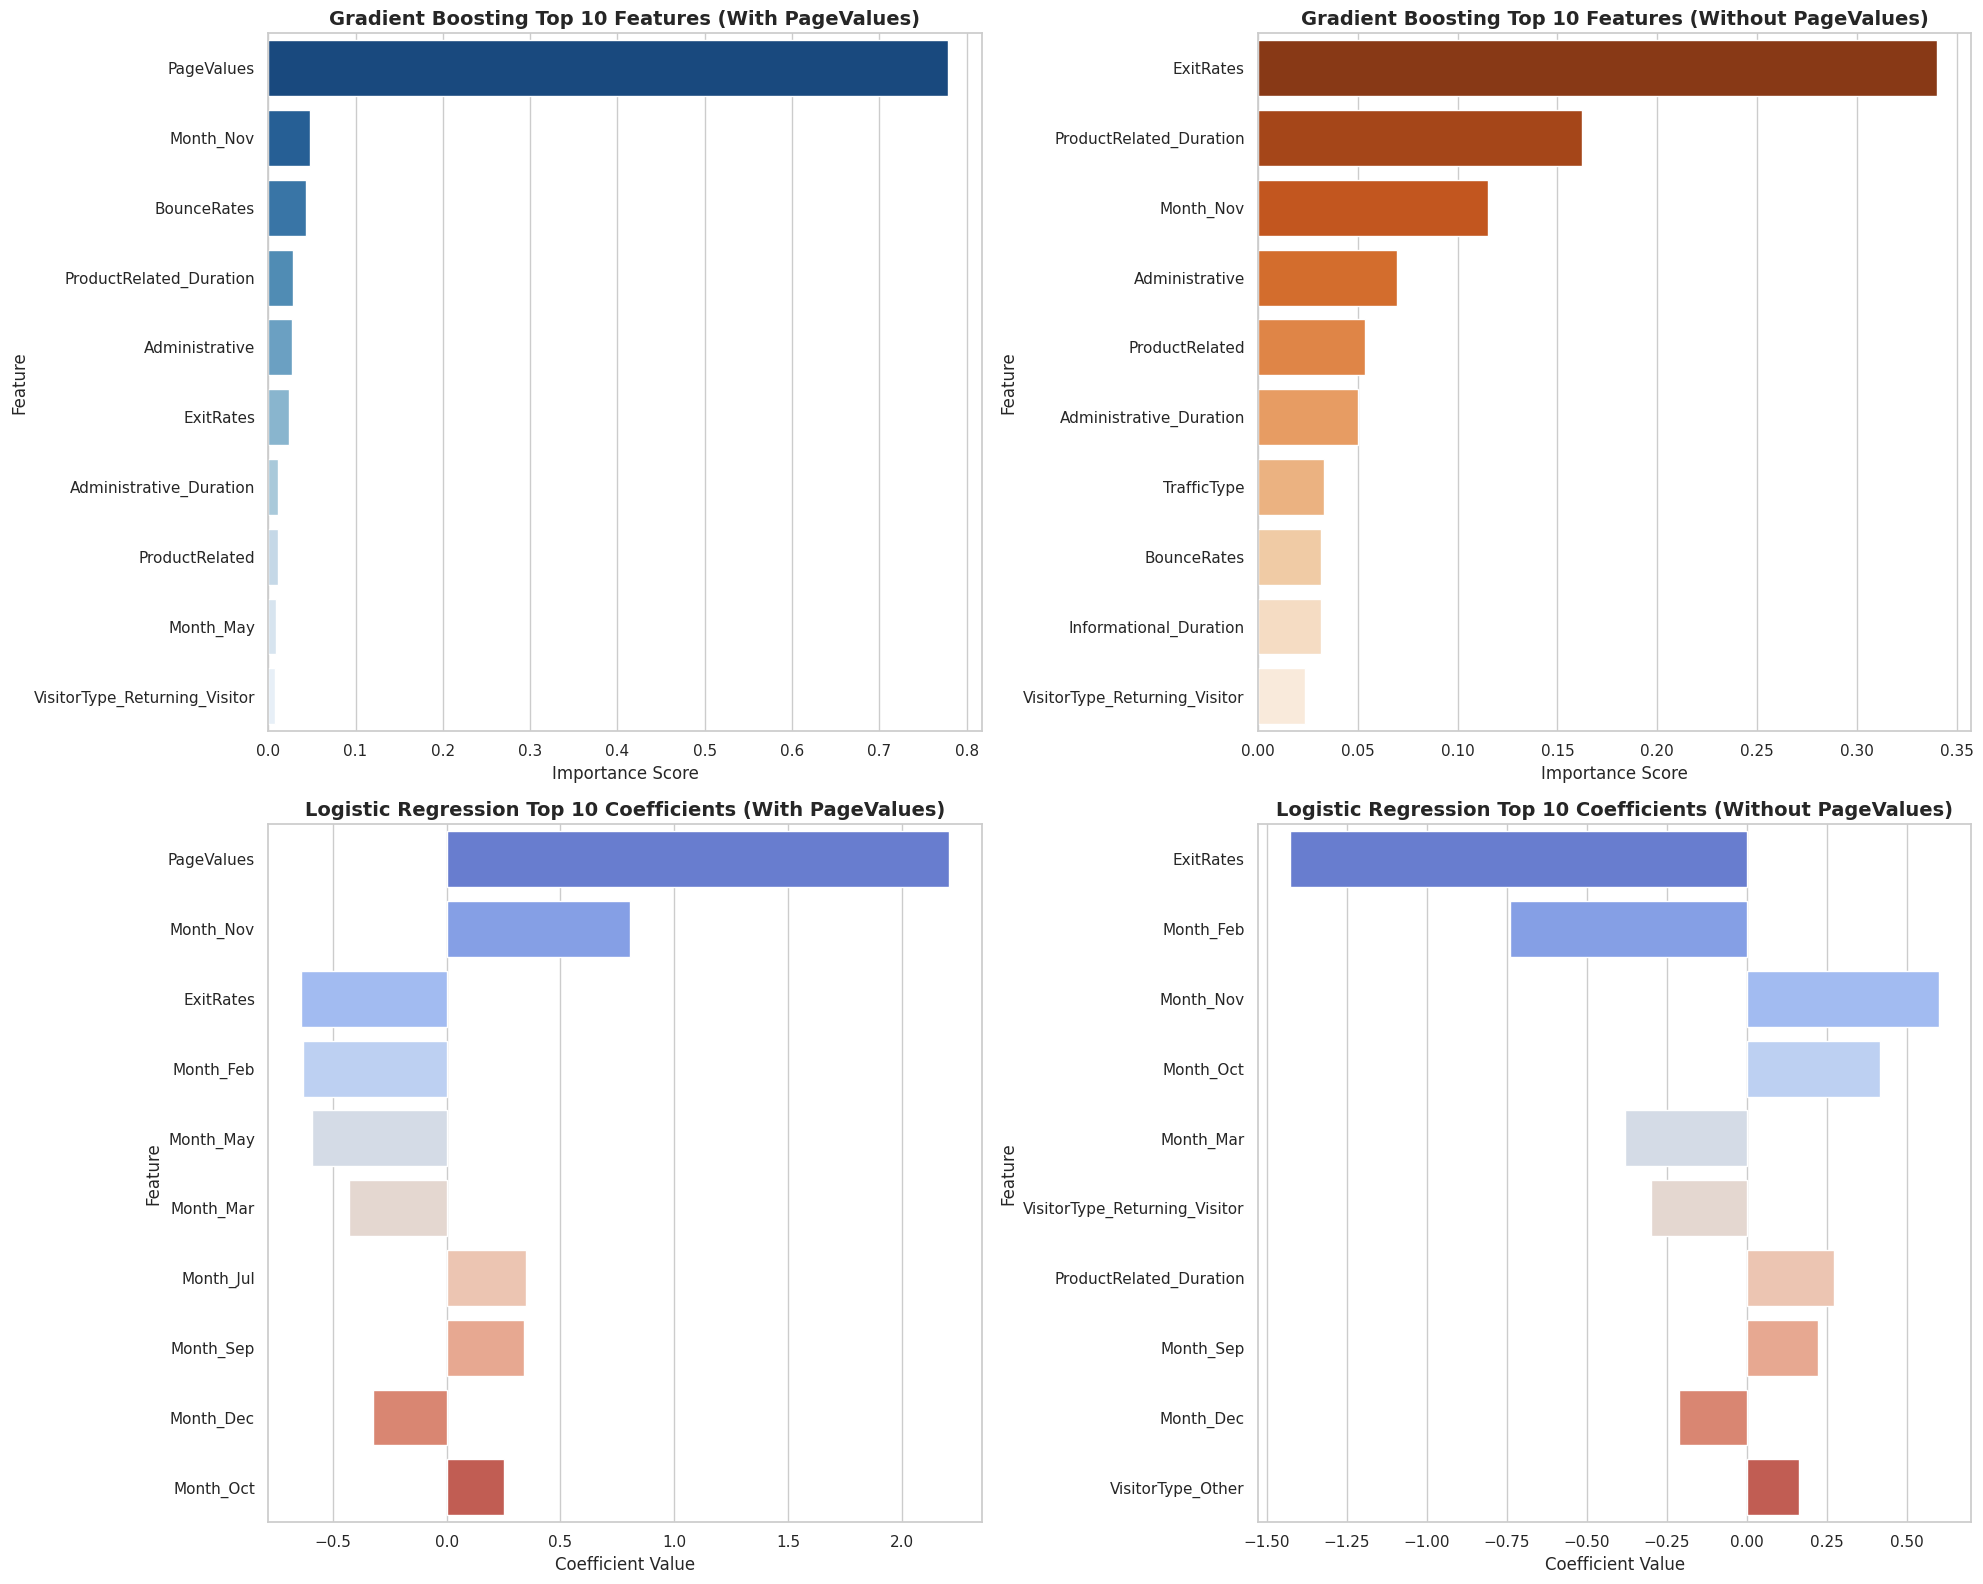

=== Top 5 Gradient Boosting Predictors (With PageValues) ===
                Feature  Importance
             PageValues    0.778216
              Month_Nov    0.047296
            BounceRates    0.043009
ProductRelated_Duration    0.028764
         Administrative    0.027540

=== Top 5 Gradient Boosting Predictors (Without PageValues) ===
                Feature  Importance
              ExitRates    0.340261
ProductRelated_Duration    0.162364
              Month_Nov    0.115256
         Administrative    0.069460
         ProductRelated    0.053699


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Retrieve feature names for both configurations
# Configuration: With PageValues
cat_encoder_with = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols_with = cat_encoder_with.get_feature_names_out(categorical_cols).tolist()
features_with = numerical_cols + encoded_cat_cols_with

# Configuration: Without PageValues
cat_encoder_no = preprocessor_no_pv.named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols_no = cat_encoder_no.get_feature_names_out(categorical_cols).tolist()
features_no = numerical_cols_no_pv + encoded_cat_cols_no

# 2. Extract importances and coefficients
# Models: Gradient Boosting, Random Forest, Logistic Regression
gb_with = experiments_results['with_pv']['Gradient Boosting']['best_estimator']
rf_with = experiments_results['with_pv']['Random Forest']['best_estimator']
lr_with = experiments_results['with_pv']['Logistic Regression']['best_estimator']

gb_no = experiments_results['no_pv']['Gradient Boosting']['best_estimator']
rf_no = experiments_results['no_pv']['Random Forest']['best_estimator']
lr_no = experiments_results['no_pv']['Logistic Regression']['best_estimator']

# Prepare DataFrames for plotting
df_imp_gb_with = pd.DataFrame({'Feature': features_with, 'Importance': gb_with.feature_importances_}).sort_values(by='Importance', ascending=False).head(10)
df_imp_gb_no = pd.DataFrame({'Feature': features_no, 'Importance': gb_no.feature_importances_}).sort_values(by='Importance', ascending=False).head(10)

df_coef_lr_with = pd.DataFrame({'Feature': features_with, 'Coefficient': lr_with.coef_[0]})
df_coef_lr_with['AbsCoef'] = df_coef_lr_with['Coefficient'].abs()
df_coef_lr_with = df_coef_lr_with.sort_values(by='AbsCoef', ascending=False).head(10)

df_coef_lr_no = pd.DataFrame({'Feature': features_no, 'Coefficient': lr_no.coef_[0]})
df_coef_lr_no['AbsCoef'] = df_coef_lr_no['Coefficient'].abs()
df_coef_lr_no = df_coef_lr_no.sort_values(by='AbsCoef', ascending=False).head(10)

# 3. Visualization subplots
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# Plot GB Feature Importance - With PageValues
sns.barplot(x='Importance', y='Feature', hue='Feature', data=df_imp_gb_with, ax=axes[0, 0], palette='Blues_r', legend=False)
axes[0, 0].set_title('Gradient Boosting Top 10 Features (With PageValues)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Importance Score')

# Plot GB Feature Importance - Without PageValues
sns.barplot(x='Importance', y='Feature', hue='Feature', data=df_imp_gb_no, ax=axes[0, 1], palette='Oranges_r', legend=False)
axes[0, 1].set_title('Gradient Boosting Top 10 Features (Without PageValues)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Importance Score')

# Plot LR Coefficients - With PageValues
sns.barplot(x='Coefficient', y='Feature', hue='Feature', data=df_coef_lr_with, ax=axes[1, 0], palette='coolwarm', legend=False)
axes[1, 0].set_title('Logistic Regression Top 10 Coefficients (With PageValues)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Coefficient Value')

# Plot LR Coefficients - Without PageValues
sns.barplot(x='Coefficient', y='Feature', hue='Feature', data=df_coef_lr_no, ax=axes[1, 1], palette='coolwarm', legend=False)
axes[1, 1].set_title('Logistic Regression Top 10 Coefficients (Without PageValues)', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Coefficient Value')

plt.tight_layout()
plt.show()

# 4. Print summaries of top ranking predictors
print("=== Top 5 Gradient Boosting Predictors (With PageValues) ===")
print(df_imp_gb_with.head(5).to_string(index=False))
print("\n=== Top 5 Gradient Boosting Predictors (Without PageValues) ===")
print(df_imp_gb_no.head(5).to_string(index=False))